# Exploratory Data Analysis
## Basic overview of the images

In [4]:
from pathlib import Path

TRAIN_PATH = Path('../data/raw/train_images/')
TEST_PATH = Path('../data/raw/test_images/')

train_files = list(TRAIN_PATH.glob('*.jpg'))
test_files = list(TEST_PATH.glob('*.jpg'))

train_files_count = len(train_files)
test_files_count = len(test_files)

test_percent = 100 * test_files_count // (test_files_count + train_files_count)

print(f'There are {train_files_count} training images and {test_files_count} '
      f'test images\n\nThis makes a test size of {test_percent}%.')


There are 5546 training images and 3698 test images

This makes a test size of 40%.


## Basic overview of the labels (DataFrame of `train.csv`)

In [5]:
import pandas as pd

df = pd.read_csv('../data/raw/train.csv')
df.info()


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 22184 entries, 0 to 22183
Data columns (total 2 columns):
 #   Column         Non-Null Count  Dtype 
---  ------         --------------  ----- 
 0   Image_Label    22184 non-null  object
 1   EncodedPixels  11836 non-null  object
dtypes: object(2)
memory usage: 346.8+ KB


In [6]:
df.head()

,Image_Label,EncodedPixels
0,0011165.jpg_Fish,20056 257 20440 257 20824 257 21208 257 21592 ...
1,0011165.jpg_Flower,102135 1 102245 275 102629 275 103013 275 1033...
2,0011165.jpg_Gravel,NaN
3,0011165.jpg_Sugar,NaN
4,002be4f.jpg_Fish,17668 241 18051 242 18435 242 18819 242 19203 ...


## Analysis of the labels

- The `df` contains 2 columns. Both are of type `object`: `Image_label` and `EncodedPixels`
- There are 4 rows per image, one for each of the categories **Fish**, **Flower**, **Gravel** and **Sugar**
- These categories are appended to the file name in the column `Image_Label`. So, this column contains two different informations that should be separated/split.
- The `EncodedPixels` :
  - Is `NaN` when a picture is not labeled for the category which is appended to the filename.
  - But if there is no `NaN` then the `EncodedPixels` column contains the **RLE encoded*** mask of the image. Within this rectangular area scientists marked the appropriate category when they spotted it in the image. Origin of this investigation seems to be [this paper](https://www.researchgate.net/publication/342432947_Combining_Crowdsourcing_and_Deep_Learning_to_Explore_the_Mesoscale_Organization_of_Shallow_Convection).


> **RLE Encoded*** The [Kaggle page](https://www.kaggle.com/competitions/understanding_cloud_organization/overview/evaluation) states about the EncodedPixels:
> 
> In order to reduce the submission file size, our metric uses run-length encoding on the pixel values. Instead of submitting an exhaustive list of indices for your segmentation, you will submit pairs of values that contain a start position and a run length. E.g. '1 3' implies starting at pixel 1 and running a total of 3 pixels (1,2,3).
> 
> The competition format requires a space delimited list of pairs. For example, '1 3 10 5' implies pixels 1,2,3,10,11,12,13,14 are to be included in the mask. The metric checks that the pairs are sorted, positive, and the decoded pixel values are not duplicated. The pixels are numbered from top to bottom, then left to right: 1 is pixel (1,1), 2 is pixel (2,1), etc.

## Adding an own column for the labels

For counting etc it is impractical to have the labels attached to the file name. It should be moved to its own column.

In [7]:
df['Label'] = df['Image_Label'].str.split('_', n=1).str[1]
df['Image_Label'] = df['Image_Label'].str.split('_', n=1).str[0]
df = df.rename({'Image_Label': 'Image'}, axis=1)
df.head()

,Image,EncodedPixels,Label
0,0011165.jpg,20056 257 20440 257 20824 257 21208 257 21592 ...,Fish
1,0011165.jpg,102135 1 102245 275 102629 275 103013 275 1033...,Flower
2,0011165.jpg,NaN,Gravel
3,0011165.jpg,NaN,Sugar
4,002be4f.jpg,17668 241 18051 242 18435 242 18819 242 19203 ...,Fish


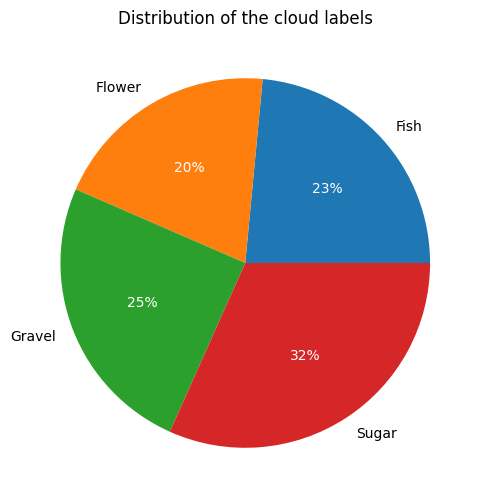

In [24]:
import matplotlib.pyplot as plt

df_no_na = df.dropna()
df_fish = df_no_na[df_no_na['Label']=='Fish']
df_flower = df_no_na[df_no_na['Label']=='Flower']
df_gravel = df_no_na[df_no_na['Label']=='Gravel']
df_sugar = df_no_na[df_no_na['Label']=='Sugar']

fish_count = len(df_fish)
flower_count = len(df_flower)
gravel_count = len(df_gravel)
sugar_count = len(df_sugar)

plt.figure(figsize=(6, 6))
wedges, texts, *rest = plt.pie(
    x=[fish_count, flower_count, gravel_count, sugar_count],
    labels=['Fish', 'Flower', 'Gravel', 'Sugar'],
    autopct='%.0f%%',   # Show percentages - and with no decimals
)

# Set the percentages colors
if len(rest) > 0:           # The autotexts are i rest[0] - but only if the
    autotexts = rest[0]     # `autopct` param is set in the chart.
    for autotext in autotexts:
        autotext.set_color('white')

    plt.title('Distribution of the cloud labels')
    plt.show()


Sugar has a much larger share than the others, which have fairly similar shares among themselves. **Could that be relevant?**